# Training CNN Model to process the reviews 

### Import Required Libraries

This cell imports all necessary libraries for building and training the CNN model:
- **Data handling**: pandas, numpy for data manipulation
- **Visualization**: matplotlib, seaborn for plotting training results
- **Machine learning**: sklearn for data splitting and evaluation metrics
- **Deep learning**: TensorFlow/Keras for building the neural network
- **Utilities**: ast, os, re, warnings for various helper functions

In [13]:
import ast
import os
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau # type: ignore
from tensorflow.keras.layers import ( # type: ignore
    Input, Embedding, Conv1D, MaxPooling1D, GlobalMaxPooling1D,
    Concatenate, Dropout, Dense, BatchNormalization
)
from tensorflow.keras.models import Sequential, Model # type: ignore
from tensorflow.keras.optimizers import Adam # type: ignore
from tensorflow.keras.utils import to_categorical # type: ignore

### Optimizer Selection

Choose from different optimizers to experiment with model performance. Each has different characteristics:
- **Adam**: Popular general-purpose optimizer, combines momentum and adaptive learning (default choice)
- **RMSprop**: Good for recurrent networks and CNNs, adapts learning rate
- **SGD**: Classic optimizer with momentum, often performs well with proper tuning
- **Nadam**: Adam with Nesterov momentum for better convergence
- **AdamW**: Adam with weight decay for better regularization (requires tensorflow-addons)

### CNN Class Definition

This cell contains:
1. **Optimizer dictionary**: Clean configuration of all available optimizers
2. **Optimizer selection**: Easy switching between optimizers by changing one variable
3. **SentimentCNN class**: Complete CNN architecture with multi-kernel convolutions, batch normalization, and dropout for sentiment analysis

In [ ]:
# Optimizer configurations
optimizers = {
    'adam': tf.keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999),
    'rmsprop': tf.keras.optimizers.RMSprop(learning_rate=0.001),
    'sgd': tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True),
    'nadam': tf.keras.optimizers.Nadam(learning_rate=0.001),
    # 'adamw': tfa.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4)  # requires tensorflow-addons
}

# Choose optimizer
chosen_optimizer = 'rmsprop'  
optimizer = optimizers[chosen_optimizer]

print(f"Using optimizer: {optimizer.__class__.__name__}")

class SentimentCNN:
    def __init__(self, vocab_size, max_length, num_classes=3, embedding_dim=128):
        self.vocab_size = vocab_size
        self.max_length = max_length
        self.num_classes = num_classes
        self.embedding_dim = embedding_dim
        self.model = None
        self.history = None
        self.build_model()
        self.compile_model()

    def build_model(self):
        
        inputs = Input(shape=(self.max_length,))
        x = Embedding(input_dim=self.vocab_size, output_dim=self.embedding_dim, input_length=self.max_length)(inputs)
        
        # Apply batch normalization after embedding
        x = BatchNormalization()(x)
        
        # Multiple convolution layers with different kernel sizes
        conv3 = Conv1D(128, kernel_size=3, activation='relu', padding='same')(x)
        conv3 = BatchNormalization()(conv3)
        
        conv4 = Conv1D(128, kernel_size=4, activation='relu', padding='same')(x)
        conv4 = BatchNormalization()(conv4)
        
        conv5 = Conv1D(128, kernel_size=5, activation='relu', padding='same')(x)
        conv5 = BatchNormalization()(conv5)
        
        # Global max pooling for each conv layer
        pool3 = GlobalMaxPooling1D()(conv3)
        pool4 = GlobalMaxPooling1D()(conv4)
        pool5 = GlobalMaxPooling1D()(conv5)
        
        # Concatenate all pooled features
        merged = Concatenate()([pool3, pool4, pool5])
        
        # Add batch normalization before dropout
        merged = BatchNormalization()(merged)
        dropout = Dropout(0.3)(merged)
        
        # Dense layer with batch normalization
        dense = Dense(128, activation='relu')(dropout)
        dense = BatchNormalization()(dense)
        dropout = Dropout(0.3)(dense)
        
        # Output layer
        outputs = Dense(self.num_classes, activation='softmax')(dropout)
        self.model = Model(inputs=inputs, outputs=outputs)
        return self.model

    def compile_model(self):
        self.model.compile(
            optimizer=optimizer,
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )

    def train(self, X_train, y_train, X_val=None, y_val=None, epochs=None, batch_size=64, verbose=1,callbacks=None):
        
        validation_data = (X_val, y_val) if X_val is not None and y_val is not None else None
        callbacks = [EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
                     ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
                     ]
        self.history = self.model.fit(
            X_train, y_train,
            validation_data=validation_data,
            epochs=epochs,
            batch_size=batch_size,
            verbose=verbose,
            callbacks=callbacks
        )
        return self.history

    def evaluate(self, X_test, y_test):
        if self.model is None:
            raise ValueError("Model not built yet!")
        loss, accuracy = self.model.evaluate(X_test, y_test, verbose=0)
        return loss, accuracy

    def predict(self, X):
        if self.model is None:
            raise ValueError("Model not built yet!")
        return self.model.predict(X)

    def predict_classes(self, X):
        predictions = self.predict(X)
        return np.argmax(predictions, axis=1)

    def get_model_summary(self):
        if self.model is None:
            raise ValueError("Model not built yet!")
        return self.model.summary()


Using optimizer: RMSprop


### Load and Display Preprocessed Data

Load the tokenized and padded dataset that was prepared in the preprocessing stage. This data contains:
- **Padded sequences**: Reviews converted to integer sequences with consistent length
- **Numerical labels**: Sentiment labels encoded as integers (0=negative, 1=neutral, 2=positive)

In [15]:
df = pd.read_csv('../../data/processed_reviews_dl.csv')
display(df)

,review,language,label,label_numerical,tokenized,padded
0,terrible,en,negative,0,[364],[364 0 0 0 0 0 0 0 0 0 0 ...
1,less movie show total money worst,en,negative,0,"[609, 337, 316, 2655, 244, 77]",[ 609 337 316 2655 244 77 0 0 0 ...
2,inapt brightness cannot brought zero even phon...,en,negative,0,"[5233, 1362, 760, 3462, 1579, 165, 367, 1362, ...",[5233 1362 760 3462 1579 165 367 1362 1867 ...
3,able login account tried uninstalling reinstat...,en,negative,0,"[798, 871, 223, 389, 2656, 3463, 18, 263, 2071...",[ 798 871 223 389 2656 3463 18 263 2071 ...
4,netflix one favourite platform watch show prob...,en,negative,0,"[231, 70, 1580, 617, 458, 316, 134, 231, 1307,...",[ 231 70 1580 617 458 316 134 231 1307 ...
...,...,...,...,...,...,...
22231,رغم ان ب عجب ناس ك تير ل كن ارا قيم مقابل ك مي...,ar,neutral,1,"[376, 10, 5, 1, 344, 7, 1836, 4, 20, 4824, 958...",[ 376 10 5 1 344 7 1836 4 20 ...
22232,ال اكل جميل جدا,ar,neutral,1,"[2, 23, 45, 9]",[ 2 23 45 9 0 0 0 0 0 0 0 0 0 0 0 ...
22233,ال دجاج و اللحوم مثلج,ar,neutral,1,"[2, 50, 3, 4820, 4096]",[ 2 50 3 4820 4096 0 0 0 0 ...
22234,ممتاز ب ل و يفتح ب المدين يصير امتز,ar,neutral,1,"[25, 5, 4, 3, 1417, 5, 8717, 1058, 1]",[ 25 5 4 3 1417 5 8717 1058 1 ...


### Dataset Overview

Quick check of the dataset size to understand the volume of data we're working with.

In [16]:
print(f"Length of DataFrame: {len(df)}")

Length of DataFrame: 22236


### Data Processing and Analysis

This cell performs several critical data preprocessing steps:
1. **Parse padded sequences**: Convert string representations back to integer lists
2. **Calculate vocabulary size**: Determine the total number of unique tokens
3. **Analyze sequence lengths**: Get statistics about review lengths
4. **Create label mapping**: Show the relationship between numerical and text labels
5. **Data splitting**: Split into train/validation/test sets with stratification to maintain class balance

In [17]:
def fix_and_parse_padded(padded_data):
    if isinstance(padded_data, list):  # already a list
        return padded_data
    if isinstance(padded_data, str):   # it's a string that needs parsing
        cleaned = re.sub(r'\s+', ',', padded_data.strip('[]'))
        return [int(num) for num in cleaned.split(',') if num.strip().isdigit()]
    return []  # fallback for invalid data

df['padded'] = df['padded'].apply(fix_and_parse_padded)


X = df['padded'].values
y = df['label_numerical'].values

display(df)

# Calculate vocabulary size properly
all_values = []
for seq in X:
    all_values.extend(seq)
vocab_size = len(set(all_values))
max_length = max(len(seq) for seq in X)

print(f"\nVocabulary size: {vocab_size}")
print(f"Max sequence length: {max_length}")
print(f"Min sequence length: {min(len(seq) for seq in X)}")
print(f"Average sequence length: {np.mean([len(seq) for seq in X]):.2f}")

# Create label mapping
label_mapping = dict(zip(df['label_numerical'], df['label']))
unique_labels = {k: v for k, v in label_mapping.items()}
print("\nLabel mapping:")
for num_label, str_label in sorted(unique_labels.items()):
    print(f"{num_label}: {str_label}")

print(f"\nData shapes:")
print(f"X shape: {X.shape}")
print(f"X dtype: {X.dtype}")
print(f"y shape: {y.shape}")
print(f"y dtype: {y.dtype}")
print(f"Number of classes: {len(np.unique(y))}")

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

print(f"\nData split:")
print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples") 
print(f"Test set: {X_test.shape[0]} samples")

,review,language,label,label_numerical,tokenized,padded
0,terrible,en,negative,0,[364],"[364, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0..."
1,less movie show total money worst,en,negative,0,"[609, 337, 316, 2655, 244, 77]","[609, 337, 316, 2655, 244, 77, 0, 0, 0, 0, 0, ..."
2,inapt brightness cannot brought zero even phon...,en,negative,0,"[5233, 1362, 760, 3462, 1579, 165, 367, 1362, ...","[5233, 1362, 760, 3462, 1579, 165, 367, 1362, ..."
3,able login account tried uninstalling reinstat...,en,negative,0,"[798, 871, 223, 389, 2656, 3463, 18, 263, 2071...","[798, 871, 223, 389, 2656, 3463, 18, 263, 2071..."
4,netflix one favourite platform watch show prob...,en,negative,0,"[231, 70, 1580, 617, 458, 316, 134, 231, 1307,...","[231, 70, 1580, 617, 458, 316, 134, 231, 1307,..."
...,...,...,...,...,...,...
22231,رغم ان ب عجب ناس ك تير ل كن ارا قيم مقابل ك مي...,ar,neutral,1,"[376, 10, 5, 1, 344, 7, 1836, 4, 20, 4824, 958...","[376, 10, 5, 1, 344, 7, 1836, 4, 20, 4824, 958..."
22232,ال اكل جميل جدا,ar,neutral,1,"[2, 23, 45, 9]","[2, 23, 45, 9, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0..."
22233,ال دجاج و اللحوم مثلج,ar,neutral,1,"[2, 50, 3, 4820, 4096]","[2, 50, 3, 4820, 4096, 0, 0, 0, 0, 0, 0, 0, 0,..."
22234,ممتاز ب ل و يفتح ب المدين يصير امتز,ar,neutral,1,"[25, 5, 4, 3, 1417, 5, 8717, 1058, 1]","[25, 5, 4, 3, 1417, 5, 8717, 1058, 1, 0, 0, 0,..."



Vocabulary size: 14330
Max sequence length: 60
Min sequence length: 60
Average sequence length: 60.00

Label mapping:
0: negative
1: neutral
2: positive

Data shapes:
X shape: (22236,)
X dtype: object
y shape: (22236,)
y dtype: int64
Number of classes: 3

Data split:
Training set: 13341 samples
Validation set: 4447 samples
Test set: 4448 samples


### Label Format Verification

Since we're using sparse categorical crossentropy, we work directly with integer labels instead of one-hot encoded vectors. This is more memory-efficient and computationally faster.

In [18]:
# Labels are already in integer format (0, 1, 2) - no need for one-hot encoding with sparse_categorical_crossentropy
print(f"Original y_train shape: {y_train.shape}")
print(f"y_val shape: {y_val.shape}")
print(f"y_test shape: {y_test.shape}")

# Example of label format
print(f"\nExample labels: {y_train[:5]} (integers, not one-hot)")

Original y_train shape: (13341,)
y_val shape: (4447,)
y_test shape: (4448,)

Example labels: [1 2 1 1 0] (integers, not one-hot)


### Model Initialization

Create and initialize the CNN model with the calculated parameters from our dataset. The model uses:
- **Multi-kernel CNN**: Different filter sizes (3, 4, 5) to capture various n-gram patterns
- **Batch normalization**: For stable training and faster convergence
- **Dropout**: For regularization to prevent overfitting
- **Sparse categorical crossentropy**: Appropriate loss function for integer labels

In [19]:
# Use already calculated model parameters
# vocab_size and max_length are already defined in previous cells

num_classes = len(np.unique(y))

# Initialize model with correct parameters
print("Model parameters:")
print(f"Vocabulary size: {vocab_size}")
print(f"Max sequence length: {max_length}")
print(f"Number of classes: {num_classes}")

# Create and compile the model
cnn_model = SentimentCNN(
    vocab_size=vocab_size,
    max_length=max_length,
    num_classes=num_classes
)

# Display model architecture
cnn_model.model.summary()

Model parameters:
Vocabulary size: 14330
Max sequence length: 60
Number of classes: 3
Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_2 (InputLayer)        [(None, 60)]                 0         []                            
                                                                                                  
 embedding_1 (Embedding)     (None, 60, 128)              1834240   ['input_2[0][0]']             
                                                                                                  
 batch_normalization_6 (Bat  (None, 60, 128)              512       ['embedding_1[0][0]']         
 chNormalization)                                                                                 
                                                                                                  
 conv1

### Model Training

Train the CNN model with the following configuration:
- **Early stopping**: Prevents overfitting by monitoring validation loss
- **Learning rate reduction**: Reduces learning rate when validation loss plateaus
- **Integer labels**: Using sparse categorical crossentropy with original integer labels
- **Data conversion**: Ensure proper data types and value clipping for embedding layer

In [20]:
# Train the model
print("Starting model training...")

# Convert object arrays to 2D numpy arrays of int32
X_train_arr = np.stack(X_train).astype(np.int32)
X_val_arr = np.stack(X_val).astype(np.int32)

# Ensure all indices are within [0, vocab_size-1]
X_train_arr = np.clip(X_train_arr, 0, vocab_size - 1)
X_val_arr = np.clip(X_val_arr, 0, vocab_size - 1)

# Use integer labels directly with sparse_categorical_crossentropy
history = cnn_model.train(
    X_train_arr, y_train,
    X_val_arr, y_val,
    epochs=30, 
    batch_size=64, 
    verbose=1,
    # callbacks=callbacks
)

print("Training completed!")

Starting model training...
Epoch 1/30
209/209 [==============================] - 28s 110ms/step - loss: 0.4895 - accuracy: 0.8260 - val_loss: 1.1473 - val_accuracy: 0.5329 - lr: 0.0010
Epoch 2/30
209/209 [==============================] - 24s 112ms/step - loss: 0.2376 - accuracy: 0.9158 - val_loss: 0.6849 - val_accuracy: 0.7025 - lr: 0.0010
Epoch 3/30
209/209 [==============================] - 24s 113ms/step - loss: 0.1433 - accuracy: 0.9506 - val_loss: 0.2868 - val_accuracy: 0.9049 - lr: 0.0010
Epoch 4/30
209/209 [==============================] - 22s 105ms/step - loss: 0.0951 - accuracy: 0.9695 - val_loss: 0.3317 - val_accuracy: 0.9038 - lr: 0.0010
Epoch 5/30
209/209 [==============================] - ETA: 0s - loss: 0.0729 - accuracy: 0.9755
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
209/209 [==============================] - 23s 108ms/step - loss: 0.0729 - accuracy: 0.9755 - val_loss: 0.3469 - val_accuracy: 0.9013 - lr: 0.0010
Epoch 6/30
209/209 [==

### Model Evaluation and Visualization

Evaluate the trained model on the test set and visualize the training progress:
- **Test evaluation**: Get final accuracy and loss metrics on unseen data
- **Training curves**: Plot accuracy and loss progression during training
- **Performance analysis**: Visualize how well the model learned over epochs

Evaluating model on test set...
Test Loss: 0.2506
Test Accuracy: 0.9236


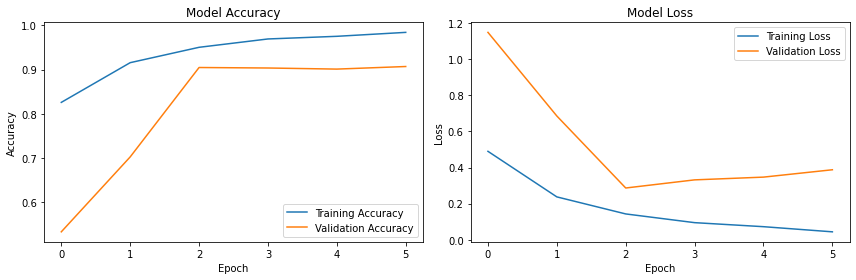

In [21]:
# Evaluate the model
print("Evaluating model on test set...")

# Convert X_test to 2D numpy array of int32
X_test_arr = np.stack(X_test).astype(np.int32)
X_test_arr = np.clip(X_test_arr, 0, vocab_size - 1)

# Use integer labels for evaluation with sparse_categorical_crossentropy
test_loss, test_accuracy = cnn_model.evaluate(X_test_arr, y_test)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Plot training history

plt.figure(figsize=(12, 4))

# Plot training & validation accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot training & validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

### Detailed Performance Analysis and Model Saving

Generate comprehensive performance metrics and save the trained model:
- **Predictions**: Generate class predictions for test data
- **Classification report**: Detailed precision, recall, and F1-scores per class
- **Confusion matrix**: Visual representation of prediction accuracy per class
- **Model persistence**: Save the trained model for future use
- **Performance summary**: Complete overview of model capabilities and results

139/139 [==============================] - 2s 13ms/step
Classification Report:
              precision    recall  f1-score   support

    negative       0.93      0.94      0.93      1474
     neutral       0.98      0.89      0.93      1500
    positive       0.87      0.94      0.90      1474

    accuracy                           0.92      4448
   macro avg       0.93      0.92      0.92      4448
weighted avg       0.93      0.92      0.92      4448



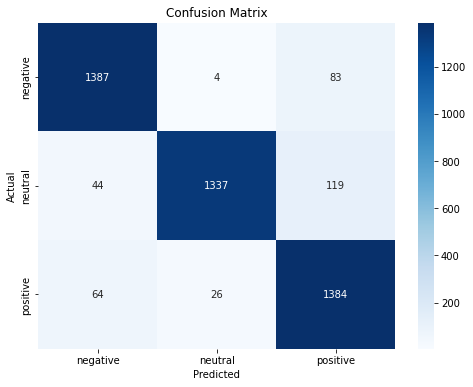

Model saved to: ../../models/sentiment_cnn_model.h5

 CNN Model training completed successfully
Final Test Accuracy: 0.9236 (92.36%)
Final Test Loss: 0.2506

 Model Performance Summary:
- Vocabulary Size: 14,330
- Max Sequence Length: 60
- Training Samples: 13,341
- Validation Samples: 4,447
- Test Samples: 4,448
- Test Accuracy: 92.36%
- Model saved to: ../../models/sentiment_cnn_model.h5


c:\Users\Administrator\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [22]:
# Detailed performance metrics

# Make predictions
y_pred = cnn_model.predict_classes(X_test_arr)

# Classification report
print("Classification Report:")

# Create target names based on label mapping
target_names = ['negative', 'neutral', 'positive']  # Based on label mapping 0, 1, 2

print(classification_report(y_test, y_pred, target_names=target_names))

# Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Create models directory if it doesn't exist
os.makedirs('../../models', exist_ok=True)

# Save the model
model_path = '../../models/sentiment_cnn_model.h5'
cnn_model.model.save(model_path)
print(f"Model saved to: {model_path}")

print("\n CNN Model training completed successfully")
print(f"Final Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Final Test Loss: {test_loss:.4f}")

# Summary of results
print("\n Model Performance Summary:")
print(f"- Vocabulary Size: {vocab_size:,}")
print(f"- Max Sequence Length: {max_length}")
print(f"- Training Samples: {len(X_train):,}")
print(f"- Validation Samples: {len(X_val):,}")
print(f"- Test Samples: {len(X_test):,}")
print(f"- Test Accuracy: {test_accuracy*100:.2f}%")
print(f"- Model saved to: {model_path}")